# 🔍 03. Vérification des étapes 1 et 2 : Inspection & Prétraitement
**Projet AutoML – Challenge Machine Learning (M1 IA, Le Mans Université)**

Ce notebook vérifie, jeu par jeu, que le package `automl/` fait bien :
1. **Étape 1 – Inspection & détection** : chargement, détection de la tâche, profil des colonnes.
2. **Étape 2 – Prétraitement** : imputation, log, mise à l'échelle, one-hot, suppression des constantes, TF-IDF.

Chaque vérification affiche ✅ (OK) ou ❌ (problème).

In [1]:
import os, sys, time
import numpy as np
import pandas as pd
import scipy.sparse as sp

# Permet d'importer le package automl/ sans l'installer
sys.path.insert(0, os.path.abspath(".."))
from automl.data import load_dataset, split_data
from automl.inspection import detect_task, inspect_data, MULTILABEL
from automl.preprocessing import build_preprocessor

# Copie locale du dépôt, sinon le répertoire du cluster Skinner
DATA_DIR = os.path.abspath("../dataset")
if not os.path.isdir(DATA_DIR):
    DATA_DIR = "/info/corpus/ChallengeMachineLearning"
DATASETS = ["data_A", "data_B", "data_C", "data_D", "data_E", "data_F"]

def check(ok, message):
    print(("✅ " if ok else "❌ ") + message)

print("Données lues dans :", DATA_DIR)

Données lues dans : C:\Users\LIONEL\Desktop\AutoML\AutoML\dataset


---
## 1. Étape 1 : chargement et détection de la tâche

On attend :

| Jeu | Tâche attendue | Particularité |
|---|---|---|
| data_A | multilabel (3) | valeurs manquantes, 13 colonnes catégorielles |
| data_B | regression | cible continue |
| data_C | multiclass_onehot (10) | 1 568 variables |
| data_D | binary | colonnes binaires |
| data_E | binary | |
| data_F | multiclass_onehot (20) | format creux, 61 188 variables |

In [2]:
ATTENDU = {
    "data_A": "multilabel", "data_B": "regression", "data_C": "multiclass_onehot",
    "data_D": "binary", "data_E": "binary", "data_F": "multiclass_onehot",
}

datasets, lignes = {}, []
for name in DATASETS:
    ds = load_dataset(os.path.join(DATA_DIR, name))
    task = detect_task(ds.y)
    datasets[name] = (ds, task)
    lignes.append({
        "Jeu": name,
        "X": ds.X.shape,
        "Format": "creux" if sp.issparse(ds.X) else "dense",
        "y": ds.y.shape,
        "Tâche détectée": f"{task.task} ({task.n_outputs})",
        "Attendue": ATTENDU[name],
    })
pd.DataFrame(lignes)

,Jeu,X,Format,y,Tâche détectée,Attendue
0,data_A,"(34190, 24)",dense,"(34190, 3)",multilabel (3),multilabel
1,data_B,"(5000, 16)",dense,"(5000,)",regression (1),regression
2,data_C,"(15000, 1568)",dense,"(15000, 10)",multiclass_onehot (10),multiclass_onehot
3,data_D,"(2984, 144)",dense,"(2984,)",binary (1),binary
4,data_E,"(3140, 259)",dense,"(3140,)",binary (1),binary
5,data_F,"(13142, 61188)",creux,"(13142, 20)",multiclass_onehot (20),multiclass_onehot


In [3]:
for name, (ds, task) in datasets.items():
    check(task.task == ATTENDU[name], f"{name} : tâche {task.task}")
    check(ds.X.shape[1] == len(ds.types), f"{name} : {ds.X.shape[1]} colonnes = {len(ds.types)} types")
    # Aller-retour : format .solution -> scikit-learn -> format .solution
    retour = task.decode_y(task.encode_y(ds.y))
    check(np.array_equal(retour, ds.y), f"{name} : encode_y / decode_y redonne exactement la solution")

✅ data_A : tâche multilabel
✅ data_A : 24 colonnes = 24 types
✅ data_A : encode_y / decode_y redonne exactement la solution
✅ data_B : tâche regression
✅ data_B : 16 colonnes = 16 types
✅ data_B : encode_y / decode_y redonne exactement la solution
✅ data_C : tâche multiclass_onehot
✅ data_C : 1568 colonnes = 1568 types
✅ data_C : encode_y / decode_y redonne exactement la solution
✅ data_D : tâche binary
✅ data_D : 144 colonnes = 144 types
✅ data_D : encode_y / decode_y redonne exactement la solution
✅ data_E : tâche binary
✅ data_E : 259 colonnes = 259 types
✅ data_E : encode_y / decode_y redonne exactement la solution
✅ data_F : tâche multiclass_onehot
✅ data_F : 61188 colonnes = 61188 types
✅ data_F : encode_y / decode_y redonne exactement la solution


---
## 2. Étape 1 : profil des données (calculé sur le train uniquement)

In [4]:
profils, decoupes = {}, {}
for name, (ds, task) in datasets.items():
    labels = task.encode_y(ds.y)
    stratify = labels if task.is_classification and task.task != MULTILABEL else None
    X_tr, X_va, X_te, y_tr, y_va, y_te = split_data(ds.X, ds.y, stratify)
    profil = inspect_data(X_tr, ds.types, y_tr)
    profil.task = task
    profils[name] = profil
    decoupes[name] = (X_tr, X_va, X_te, task.encode_y(y_tr), task.encode_y(y_va), task.encode_y(y_te))
    print(f"===== {name} =====")
    print(profil.summary(), "\n")

===== data_A =====
  Exemples x variables : 23932 x 24
  Format               : dense (densité 83.3%)
  Types de colonnes    : 11 num., 13 catég., 0 binaires
  Colonnes constantes  : 0
  Colonnes asymétriques: 6
  Valeurs manquantes   : 6 colonnes
  Tâche                : multilabel (3 sortie(s))
  Ratio min/max classes: 0.17 -> déséquilibré 

===== data_B =====
  Exemples x variables : 3500 x 16
  Format               : dense (densité 100.0%)
  Types de colonnes    : 16 num., 0 catég., 0 binaires
  Colonnes constantes  : 0
  Colonnes asymétriques: 8
  Valeurs manquantes   : 0 colonnes
  Tâche                : regression (1 sortie(s)) 



===== data_C =====
  Exemples x variables : 10500 x 1568
  Format               : dense (densité 58.2%)
  Types de colonnes    : 1564 num., 0 catég., 4 binaires
  Colonnes constantes  : 0
  Colonnes asymétriques: 1084
  Valeurs manquantes   : 0 colonnes
  Tâche                : multiclass_onehot (10 sortie(s))
  Ratio min/max classes: 0.75 



===== data_D =====
  Exemples x variables : 2088 x 144
  Format               : dense (densité 21.8%)
  Types de colonnes    : 8 num., 0 catég., 135 binaires
  Colonnes constantes  : 1
  Colonnes asymétriques: 2
  Valeurs manquantes   : 0 colonnes
  Tâche                : binary (1 sortie(s))
  Ratio min/max classes: 1.00 



===== data_E =====
  Exemples x variables : 2197 x 259
  Format               : dense (densité 100.0%)
  Types de colonnes    : 259 num., 0 catég., 0 binaires
  Colonnes constantes  : 0
  Colonnes asymétriques: 0
  Valeurs manquantes   : 0 colonnes
  Tâche                : binary (1 sortie(s))
  Ratio min/max classes: 0.99 



===== data_F =====
  Exemples x variables : 9198 x 61188
  Format               : creux (densité 0.2%)
  Types de colonnes    : 53580 num., 0 catég., 0 binaires
  Colonnes constantes  : 7608
  Colonnes asymétriques: 0
  Valeurs manquantes   : 0 colonnes
  Tâche                : multiclass_onehot (20 sortie(s))
  Ratio min/max classes: 0.60 



In [5]:
pA, pD, pF = profils["data_A"], profils["data_D"], profils["data_F"]
check(len(pA.categorical) == 13, "data_A : 13 colonnes catégorielles détectées")
check(pA.has_missing, f"data_A : valeurs manquantes détectées dans {len(pA.missing)} colonnes")
check(len(pD.constant) >= 1, f"data_D : {len(pD.constant)} colonne(s) constante(s) détectée(s)")
check(pF.is_sparse and pF.nonnegative_integer, "data_F : creux + données de comptage -> TF-IDF")

# Découpage 70 / 15 / 15
for name, (X_tr, X_va, X_te, *_ ) in decoupes.items():
    n = X_tr.shape[0] + X_va.shape[0] + X_te.shape[0]
    check(abs(X_tr.shape[0] / n - 0.70) < 0.01, f"{name} : train {X_tr.shape[0]} / valid {X_va.shape[0]} / test {X_te.shape[0]}")

✅ data_A : 13 colonnes catégorielles détectées
✅ data_A : valeurs manquantes détectées dans 6 colonnes
✅ data_D : 1 colonne(s) constante(s) détectée(s)
✅ data_F : creux + données de comptage -> TF-IDF
✅ data_A : train 23932 / valid 5129 / test 5129
✅ data_B : train 3500 / valid 750 / test 750
✅ data_C : train 10500 / valid 2250 / test 2250
✅ data_D : train 2088 / valid 448 / test 448
✅ data_E : train 2197 / valid 472 / test 471
✅ data_F : train 9198 / valid 1972 / test 1972


In [6]:
# Stratification : la proportion de chaque classe doit être la même dans train et valid
for name in ["data_C", "data_D", "data_E", "data_F"]:
    _, _, _, y_tr, y_va, _ = decoupes[name]
    classes = np.unique(y_tr)
    p_tr = np.array([np.mean(y_tr == c) for c in classes])
    p_va = np.array([np.mean(y_va == c) for c in classes])
    check(np.abs(p_tr - p_va).max() < 0.01, f"{name} : écart max de proportion de classe train/valid = {np.abs(p_tr - p_va).max():.4f}")

✅ data_C : écart max de proportion de classe train/valid = 0.0003
✅ data_D : écart max de proportion de classe train/valid = 0.0000
✅ data_E : écart max de proportion de classe train/valid = 0.0008
✅ data_F : écart max de proportion de classe train/valid = 0.0003


---
## 3. Étape 2 : prétraitement

Le préprocesseur est **ajusté sur le train**, puis appliqué au valid et au test.

In [7]:
resultats, transformes = [], {}
for name, profil in profils.items():
    X_tr, X_va, X_te, y_tr, y_va, y_te = decoupes[name]
    t = time.time()
    prep = build_preprocessor(profil)
    Xt_tr = prep.fit_transform(X_tr, y_tr)
    Xt_va = prep.transform(X_va)
    transformes[name] = (prep, Xt_tr, Xt_va)
    valeurs = Xt_tr.data if sp.issparse(Xt_tr) else Xt_tr
    resultats.append({
        "Jeu": name,
        "Variables avant": X_tr.shape[1],
        "Variables après": Xt_tr.shape[1],
        "Creux": sp.issparse(Xt_tr),
        "NaN restants": int(np.isnan(valeurs).sum()),
        "Temps (s)": round(time.time() - t, 1),
    })
pd.DataFrame(resultats)

,Jeu,Variables avant,Variables après,Creux,NaN restants,Temps (s)
0,data_A,24,173,False,0,0.9
1,data_B,16,16,False,0,0.0
2,data_C,1568,1568,False,0,8.0
3,data_D,144,143,False,0,0.3
4,data_E,259,259,False,0,0.2
5,data_F,61188,53580,True,0,0.3


In [8]:
for r in resultats:
    check(r["NaN restants"] == 0, f"{r['Jeu']} : aucune valeur manquante après prétraitement")
for name, (prep, Xt_tr, Xt_va) in transformes.items():
    check(Xt_tr.shape[1] == Xt_va.shape[1], f"{name} : train et valid ont le même nombre de colonnes")
check(sp.issparse(transformes["data_F"][1]), "data_F : la matrice reste creuse (pas de conversion en dense)")
check(transformes["data_A"][1].shape[1] > 24, "data_A : one-hot des catégorielles (plus de colonnes qu'au départ)")
check(transformes["data_D"][1].shape[1] == 144 - len(pD.constant), "data_D : colonne(s) constante(s) supprimée(s)")

✅ data_A : aucune valeur manquante après prétraitement
✅ data_B : aucune valeur manquante après prétraitement
✅ data_C : aucune valeur manquante après prétraitement
✅ data_D : aucune valeur manquante après prétraitement
✅ data_E : aucune valeur manquante après prétraitement
✅ data_F : aucune valeur manquante après prétraitement
✅ data_A : train et valid ont le même nombre de colonnes
✅ data_B : train et valid ont le même nombre de colonnes
✅ data_C : train et valid ont le même nombre de colonnes
✅ data_D : train et valid ont le même nombre de colonnes
✅ data_E : train et valid ont le même nombre de colonnes
✅ data_F : train et valid ont le même nombre de colonnes
✅ data_F : la matrice reste creuse (pas de conversion en dense)
✅ data_A : one-hot des catégorielles (plus de colonnes qu'au départ)
✅ data_D : colonne(s) constante(s) supprimée(s)


### Mise à l'échelle et absence de fuite de données

Les colonnes numériques passées par `StandardScaler` doivent avoir, **sur le train**, une moyenne ≈ 0 et un écart-type ≈ 1.
Sur le valid, elles doivent être proches mais **pas exactement** 0 et 1 : c'est la preuve que le scaler n'a vu que le train.

In [9]:
for name in ["data_B", "data_C", "data_E"]:
    _, Xt_tr, Xt_va = transformes[name]
    n_num = len(profils[name].numerical)      # les numériques sont les premières colonnes
    m_tr, s_tr = Xt_tr[:, :n_num].mean(), Xt_tr[:, :n_num].std(axis=0).mean()
    m_va = Xt_va[:, :n_num].mean()
    check(abs(m_tr) < 1e-6 and abs(s_tr - 1) < 1e-6, f"{name} : train moyenne={m_tr:.1e}, écart-type={s_tr:.3f}")
    check(m_va != 0, f"{name} : valid moyenne={m_va:.4f} (≠ 0, pas de fuite)")

✅ data_B : train moyenne=7.1e-16, écart-type=1.000
✅ data_B : valid moyenne=0.0047 (≠ 0, pas de fuite)


✅ data_C : train moyenne=4.7e-18, écart-type=1.000
✅ data_C : valid moyenne=0.0009 (≠ 0, pas de fuite)
✅ data_E : train moyenne=-4.2e-16, écart-type=1.000
✅ data_E : valid moyenne=0.0023 (≠ 0, pas de fuite)


### Effet du log sur les variables asymétriques (data_B)

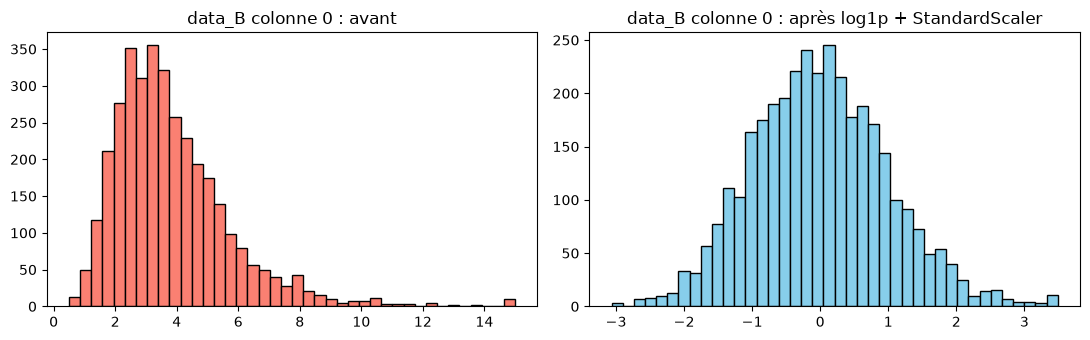

In [10]:
import matplotlib.pyplot as plt

ds_B = datasets["data_B"][0]
X_tr_B = decoupes["data_B"][0]
j = profils["data_B"].skewed[0]
colonnes_log = profils["data_B"].skewed
num_plain = [c for c in profils["data_B"].numerical if c not in colonnes_log]
pos = len(num_plain) + colonnes_log.index(j)   # position de la colonne après prétraitement

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(X_tr_B[:, j], bins=40, color="salmon", edgecolor="black")
axes[0].set_title(f"data_B colonne {j} : avant")
axes[1].hist(transformes["data_B"][1][:, pos], bins=40, color="skyblue", edgecolor="black")
axes[1].set_title(f"data_B colonne {j} : après log1p + StandardScaler")
plt.tight_layout()
plt.show()

---
## 4. Test de bout en bout avec `automl.fit`

L'interface officielle doit enchaîner les deux étapes toute seule.

In [11]:
import automl

modele = automl.AutoML().fit(os.path.join(DATA_DIR, "data_A"))
Xt_tr, y_tr = modele.splits["train"]
check(Xt_tr.shape[0] == len(y_tr), f"automl.fit : train prétraité {Xt_tr.shape}, y {y_tr.shape}")
check(set(modele.splits) == {"train", "valid", "test"}, "automl.fit : jeux train / valid / test disponibles")

[AutoML] Entraînement sur C:\Users\LIONEL\Desktop\AutoML\AutoML\dataset\data_A...


[AutoML] Jeu data_A :
  Exemples x variables : 23932 x 24
  Format               : dense (densité 83.3%)
  Types de colonnes    : 11 num., 13 catég., 0 binaires
  Colonnes constantes  : 0
  Colonnes asymétriques: 6
  Valeurs manquantes   : 6 colonnes
  Tâche                : multilabel (3 sortie(s))
  Ratio min/max classes: 0.17 -> déséquilibré


[AutoML] Après prétraitement : 173 variables
✅ automl.fit : train prétraité (23932, 173), y (23932, 3)
✅ automl.fit : jeux train / valid / test disponibles
